# 01 - Exponential growth: the Malthus model

**MATH 331 - Differential Equations.** Lecture plan: Sessions 3, 4 and 7 (the first model of the course, from the words to the prediction).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 0.2** (Example 0.2.1, the bacteria; Exercise 0.2.10),
  Section 0.3 (classification), Section 1.3 (separable equations), Exercise 1.4.13.
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Section 1.1
  (the Malthusian growth law).
* Exercise numbers of Lebl are those of the lists at the end of each chapter of the LibreTexts
  edition.
* Related notebooks: 09 (slope fields), 10 (separable equations), 11 (existence and uniqueness),
  02 (the same equation with $k < 0$), 03 (what replaces this model when resources are limited).

**What you will learn**
1. How a sentence ("the rate of growth is proportional to the population") becomes an initial
   value problem.
2. How to solve it, check it, and fit it to two measurements.
3. What the solution looks like: the slope field, the doubling time, a straight line on a
   logarithmic scale.
4. What the model does **not** say about the real world.

## 1. Theory in brief

**The model.** $P(t)$ is the size of a population at time $t$. If each individual contributes to
the growth in the same way, the rate of growth is proportional to the population:

$$ \boxed{\;\frac{dP}{dt} = k\,P, \qquad P(t_0) = P_0\;} $$

* $k$ is the **growth rate**, in units of 1/time: the growth per unit of population,
  $\tfrac{1}{P}\tfrac{dP}{dt}$. For $k < 0$ the population decays (notebook 02).
* The equation is of first order, linear, and **autonomous** (the right-hand side does not
  contain $t$). It is separable (notebook 10).

**The solution.** $\;P(t) = P_0\,e^{k\,(t - t_0)}$. It exists for all $t$ and it is the only one
(notebook 11).

**Doubling time.** $\;T_2 = \dfrac{\ln 2}{k}$: the population doubles every $T_2$, whatever its
size and whatever the starting time.

**To fit the model** two measurements are needed, because there are two unknowns, $P_0$ and $k$:
$\;k = \dfrac{\ln(P_2/P_1)}{t_2 - t_1}$.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: exponential_solution, growth_rate_from_two_values, slope_field, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. From words to an equation

Bacteria on a Petri dish, with plenty of food and space (Lebl, Section 0.2). A population twice
as large produces twice as many new bacteria per second. In symbols: the rate of change of $P$
is proportional to $P$,

$$ \frac{dP}{dt} = k\,P . $$

What the model **assumes**: unlimited resources; no effect of crowding; a population so large
that we can treat the whole number $P$ as a smooth function of time. Keep these in mind: Section
7 comes back to them.

The same equation is the *Malthusian growth law* of Adkins and Davidson (Section 1.1), and, with
other letters, continuous compound interest, radioactive decay ($k < 0$, notebook 02) and the
discharge of a capacitor (notebook 13).

## 3. Solve it by hand, then with SymPy

The steps of notebook 10, with the initial condition at the end:

0. $P = 0$ is a solution (an empty dish stays empty). From now on $P \ne 0$.
1. Separate: $\;\dfrac{dP}{P} = k\,dt$.
2. Integrate: $\;\ln|P| = k\,t + C$.
3. Solve for $P$: $\;P = D\,e^{k t}$, with $D = \pm e^{C}$, and $D = 0$ gives back step 0.
4. Initial condition: $P(t_0) = D\,e^{k t_0} = P_0$, so $\;P(t) = P_0\,e^{k\,(t - t_0)}$.
   Check: $P' = k\,P_0\,e^{k(t - t_0)} = k\,P$.

**Doubling time.** $P(t + T_2) = 2P(t)$ means $e^{k T_2} = 2$: $\;T_2 = \dfrac{\ln 2}{k}$. Neither
$t$ nor $P_0$ appears in it.

In [2]:
t, k, C, T = sp.symbols("t k C T")
P = sp.symbols("P", positive=True)
P_0, t_0 = sp.symbols("P_0 t_0")


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution (notebook 09)
    return sp.simplify(left - right)


left = sp.integrate(1 / P, P)                  # step 2, left side
right = sp.integrate(k, t)                     # step 2, right side
print("integrals:", left, "=", right, "+ C")
print("solved for P:", sp.solve(sp.Eq(left, right + C), P))        # step 3

solution = P_0 * sp.exp(k * (t - t_0))         # step 4
print("residual of P0 exp(k (t - t0)):", residual(sp.diff(solution, t), k * solution))
print("doubling time:", sp.solve(sp.Eq(sp.exp(k * T), 2), T))

assert residual(sp.diff(solution, t), k * solution) == 0
assert solution.subs(t, t_0) == P_0

integrals: log(P) = k*t + C


solved for P: [exp(C + k*t)]
residual of P0 exp(k (t - t0)): 0
doubling time: [log(2)/k]


## 4. A worked example: fit the model to two measurements

*Lebl, Example 0.2.1.* There are 100 bacteria at time 0 and 200 bacteria 10 seconds later. How
many bacteria will there be one minute from time 0?

By hand: $P_0 = 100$; $P(10) = 100\,e^{10k} = 200$ gives $k = \dfrac{\ln 2}{10} \approx 0.0693$
per second (the doubling time is 10 s, as the data say). Then

$$ P(60) = 100\,e^{6\ln 2} = 100 \cdot 2^6 = 6400 . $$

Lebl adds $P(61) \approx 6859.35$: the model happily returns a population that is not a whole
number. The computer reproduces both values; the `assert` line stops the notebook if they
disagree with the book.

In [3]:
T_FIRST, P_FIRST = 0.0, 100.0               # first measurement: seconds, bacteria
T_SECOND, P_SECOND = 10.0, 200.0            # second measurement
T_ASKED = 60.0                              # one minute

k_bacteria = ol.growth_rate_from_two_values(T_FIRST, P_FIRST, T_SECOND, P_SECOND)
P_minute = ol.exponential_solution(T_ASKED, P_FIRST, k_bacteria)
P_later = ol.exponential_solution(T_ASKED + 1, P_FIRST, k_bacteria)

print(f"k = {k_bacteria:.5f} per second,  doubling time = {np.log(2) / k_bacteria:.2f} s")
print(f"P(60) = {P_minute:.2f},  P(61) = {P_later:.2f}")
assert np.isclose(P_minute, 6400) and np.isclose(P_later, 6859.35, atol=0.01)      # Lebl, Example 0.2.1

k = 0.06931 per second,  doubling time = 10.00 s
P(60) = 6400.00,  P(61) = 6859.35


## 5. The picture: slope field and solutions

At every point $(t, P)$ the equation gives the slope $kP$ of the solution through that point
(notebook 09). Two things can be read from the equation before any computation:

* the slope depends on $P$ only, so the picture is the same in every column;
* on the line $P = 0$ the slope is zero: it is the **equilibrium** solution, and no other
  solution can cross it (notebook 11).

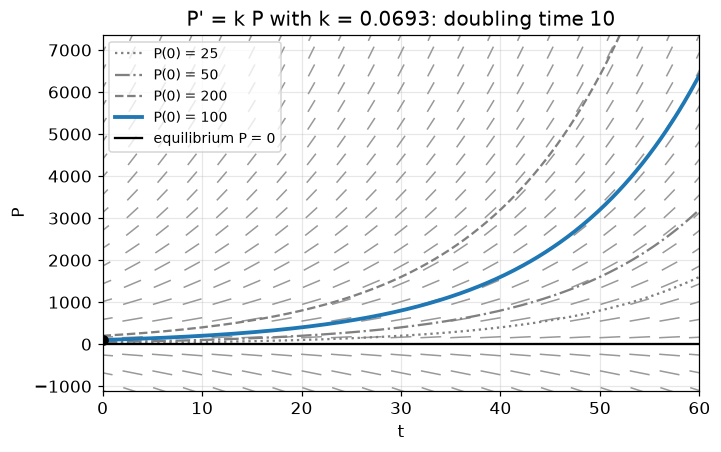

In [4]:
FIGURE_SIZE = (7.0, 4.2)
WIDE_FIGURE = (9.0, 3.6)
N_POINTS = 400
NEIGHBOURS = (0.25, 0.5, 2.0)               # other solutions: these multiples of P0
NEIGHBOUR_STYLES = (":", "-.", "--")
MARGIN = 1.15                               # the window is a little larger than the solution
BELOW = 0.15                                # and shows a little of the other side of P = 0


def plot_growth(k=k_bacteria, P0=P_FIRST, t_end=T_ASKED):
    # slope field of P' = k P with the solution through (0, P0) and three neighbours
    times = np.linspace(0.0, t_end, N_POINTS)
    top = MARGIN * max(abs(ol.exponential_solution(t_end, P0, k)), abs(P0), 1.0)
    window = (-top, BELOW * top) if P0 < 0 else (-BELOW * top, top)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, lambda tt, pp: k * pp, (0.0, t_end), window)
    for factor, style in zip(NEIGHBOURS, NEIGHBOUR_STYLES):
        ax.plot(times, ol.exponential_solution(times, factor * P0, k), linestyle=style, color="gray",
                label=f"P(0) = {factor * P0:g}")
    ax.plot(times, ol.exponential_solution(times, P0, k), "-", linewidth=2.5, label=f"P(0) = {P0:g}")
    ax.axhline(0.0, color="black", linewidth=1.5, label="equilibrium P = 0")
    ax.plot(0.0, P0, "o", color="black")
    if k > 0:
        what = f"doubling time {np.log(2) / k:.3g}"
    elif k < 0:
        what = f"half-life {np.log(2) / -k:.3g}"
    else:
        what = "nothing changes"
    ax.set_xlabel("t")
    ax.set_ylabel("P")
    ax.set_title(f"P' = k P with k = {k:.4f}: {what}")
    ax.legend(loc="upper left")
    plt.show()


plot_growth()

*The plot shows* the slope field of $P' = kP$ for the bacteria ($k = 0.0693$ per second) over one
minute. The thick curve starts at the black dot, $P(0) = 100$, and bends upwards more and more
steeply, reaching 6400. Three grey curves start from 25, 50 and 200 (dotted, dash-dot, dashed):
same shape, never touching each other. The black horizontal line is the equilibrium $P = 0$.

**Sliders.** Answer *before* moving them:

1. If $k$ is doubled, what happens to the doubling time?
2. Does the doubling time change if you start from 200 bacteria instead of 100?
3. What do the solutions look like for a negative $k$? And for a negative $P(0)$ (which the
   mathematics allows, even if a population does not)?

In [5]:
K_RANGE = (-0.1, 0.15, 0.0005)              # minimum, maximum, step (per second)
P0_RANGE = (-100.0, 500.0, 10.0)
TIME_RANGE = (5.0, 120.0, 5.0)

interact(plot_growth,
         k=FloatSlider(value=round(k_bacteria, 4), min=K_RANGE[0], max=K_RANGE[1], step=K_RANGE[2],
                       readout_format=".4f", description="k", continuous_update=False),
         P0=FloatSlider(value=P_FIRST, min=P0_RANGE[0], max=P0_RANGE[1], step=P0_RANGE[2],
                        description="P(0)", continuous_update=False),
         t_end=FloatSlider(value=T_ASKED, min=TIME_RANGE[0], max=TIME_RANGE[1], step=TIME_RANGE[2],
                           description="t max", continuous_update=False));

interactive(children=(FloatSlider(value=0.0693, continuous_update=False, description='k', max=0.15, min=-0.1, ...

(1: it is halved. 2: no. 3: for $k < 0$ every solution decays towards the equilibrium; for
$P(0) < 0$ the picture is the mirror image, below the axis.)

## 6. How to recognise exponential growth

The computer can solve the equation without the formula (`solve_ivp`, as in notebook 08). Here
we know the formula, so we can compare. The same curve is drawn twice: on ordinary axes, and with
a **logarithmic** vertical axis. Since

$$ \ln P = \ln P_0 + k\,t , $$

on the logarithmic axis an exponential is a **straight line** of slope $k$. This is how growth
of this kind is recognised in data, and how $k$ is measured.

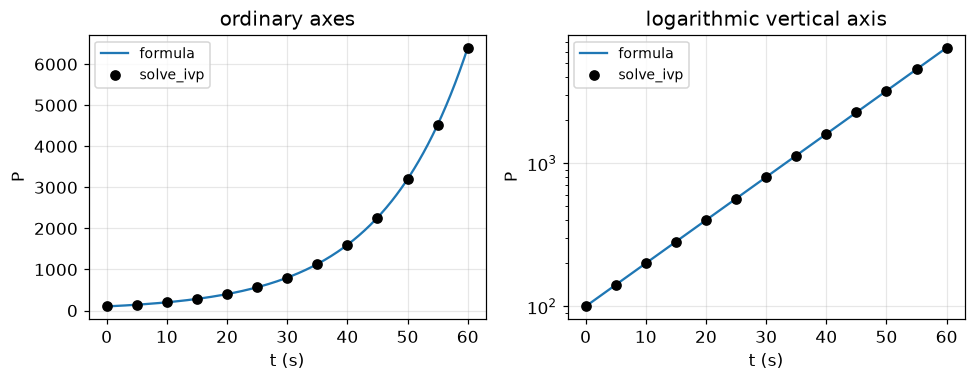

slope of the line on the logarithmic axis: 0.06931   k = 0.06931
solve_ivp: P(60) = 6400.0000  (formula: 6400)


In [6]:
N_DOTS = 13
TOLERANCE = 1e-10

numerical = solve_ivp(lambda tt, pp: k_bacteria * pp, (0.0, T_ASKED), [P_FIRST], dense_output=True,
                      rtol=TOLERANCE, atol=TOLERANCE)
t_fine = np.linspace(0.0, T_ASKED, N_POINTS)
t_dots = np.linspace(0.0, T_ASKED, N_DOTS)

fig, axes = plt.subplots(1, 2, figsize=WIDE_FIGURE)
for ax, title in zip(axes, ("ordinary axes", "logarithmic vertical axis")):
    ax.plot(t_fine, ol.exponential_solution(t_fine, P_FIRST, k_bacteria), "-", label="formula")
    ax.plot(t_dots, numerical.sol(t_dots)[0], "o", color="black", label="solve_ivp")
    ax.set_xlabel("t (s)")
    ax.set_ylabel("P")
    ax.set_title(title)
    ax.legend(loc="upper left")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

slope = np.polyfit(t_dots, np.log(numerical.sol(t_dots)[0]), 1)[0]      # the straight line through the dots
print(f"slope of the line on the logarithmic axis: {slope:.5f}   k = {k_bacteria:.5f}")
print(f"solve_ivp: P(60) = {numerical.sol(T_ASKED)[0]:.4f}  (formula: 6400)")
assert np.isclose(slope, k_bacteria) and np.isclose(numerical.sol(T_ASKED)[0], P_minute)

*The plot shows* two panels with the same data: a curve (formula) and black dots (numerical
solution), which agree. On the left, with ordinary axes, the curve stays low for most of the
minute and then shoots up to 6400. On the right, with a logarithmic vertical axis, the same
points lie on a straight line from 100 to 6400; its slope is $k$.

## 7. What the model says, and what it does not

* **A prediction, not a certainty.** $P(60) = 6400$ means *about* 6400, **if** the assumptions of
  Section 2 hold (Lebl, Section 0.2).
* **Growth without limit is not realistic.** $P(t) \to \infty$: sooner or later food and space
  run out and the growth rate must fall. That is the **logistic model** of notebook 03.
* **Long-term predictions are fragile.** If $k$ is wrong by $\delta k$, the prediction at time
  $t$ is wrong by the relative amount $\delta P / P \approx t\,\delta k$, which grows with $t$
  (Exercise 4).
* **The same mathematics, other stories:** compound interest, radioactive decay (notebook 02),
  cooling and circuits (notebook 13).

## 8. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* A quantity grows with $k = 0.03$ per year (about 3 % a year). **About** how many years does it
  take to double? (A whole number is enough; $\ln 2 \approx 0.69$.)
* By which factor is a population multiplied after three doubling times?

In [7]:
my_doubling_years = None
my_factor = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

RATE = 0.03                     # per year
ROUGHLY = 5e-2                  # an answer within five per cent is accepted
ol.check("Exercise 1, doubling time", my_doubling_years, np.log(2) / RATE, tol=ROUGHLY)
ol.check("Exercise 1, factor", my_factor, 2 ** 3);

Exercise 1, doubling time: no answer yet (replace None with your value)
Exercise 1, factor: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 0.2.10.* The population of city X was 100 thousand 20 years ago, and 120
thousand 10 years ago. Assuming exponential growth, find the growth rate $k$ (per year, three
decimals) and estimate the population now (in thousands).

**(b)** *Adapted from Lebl, Exercise 1.4.13* (which asks for $P(5)$: that is Exercise 2 of notebook
11). Bacteria grow while a toxic substance is slowly added: $P' = (2 - 0.1\,t)\,P$. The growth rate
now depends on time. Without solving: at which time $t$ is the population largest?

In [8]:
my_rate = None                  # (a): k, per year
my_population = None            # (a): thousands, now
my_time_of_maximum = None       # (b)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

YEARS_AGO = (20.0, 10.0)        # the two measurements were taken this many years ago
THOUSANDS = (100.0, 120.0)
THREE_DECIMALS = 5e-4           # 0.018 is accepted, 0.019 is not
ONE_PER_CENT = 1e-2

city_rate = ol.growth_rate_from_two_values(-YEARS_AGO[0], THOUSANDS[0], -YEARS_AGO[1], THOUSANDS[1])
city_now = ol.exponential_solution(0.0, THOUSANDS[0], city_rate, t0=-YEARS_AGO[0])
assert np.isclose(city_now, 144.0)                       # 100 times 1.2 squared

ol.check("Exercise 2a, rate", my_rate, city_rate, tol=THREE_DECIMALS)
ol.check("Exercise 2a, population", my_population, city_now, tol=ONE_PER_CENT)
ol.check("Exercise 2b", my_time_of_maximum, 2 / 0.1);

Exercise 2a, rate: no answer yet (replace None with your value)
Exercise 2a, population: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `growth_rate`, which fits the model to two measurements $(t_1, P_1)$ and
$(t_2, P_2)$: use the formula of Section 1 (`np.log` is the natural logarithm). The next cell
tries it on the bacteria of Lebl and on the city of Exercise 2.

In [9]:
def growth_rate(t1, P1, t2, P2):
    return None                 # replace None with the formula

In [10]:
if growth_rate(T_FIRST, P_FIRST, T_SECOND, P_SECOND) is None:
    print("Exercise 3: complete growth_rate first")
else:
    assert np.isclose(growth_rate(T_FIRST, P_FIRST, T_SECOND, P_SECOND), np.log(2) / T_SECOND), \
        "the bacteria double in 10 seconds: k must be ln 2 / 10"
    assert np.isclose(growth_rate(-YEARS_AGO[0], THOUSANDS[0], -YEARS_AGO[1], THOUSANDS[1]), city_rate), \
        "wrong rate for the city of Exercise 2"
    assert np.isclose(growth_rate(T_SECOND, P_SECOND, T_FIRST, P_FIRST), np.log(2) / T_SECOND), \
        "the order of the two measurements must not matter"
    assert np.isclose(growth_rate(T_FIRST, P_SECOND, T_SECOND, P_FIRST), -np.log(2) / T_SECOND), \
        "a population that halves in 10 seconds has a negative k"
    print(f"Exercise 3: correct, k = {growth_rate(T_FIRST, P_FIRST, T_SECOND, P_SECOND):.5f} per second for the bacteria")

Exercise 3: complete growth_rate first


### Exercise 4 - Explore

The growth rate of the bacteria was found from two counts, and counts are never exact. Suppose
the true $k$ is 1 % larger than $\ln 2 / 10$.

* Compute the new $P(60)$ with `ol.exponential_solution`. By how many per cent does it change?
* Do the same for $P(600)$ (ten minutes). Compare with the rule $\delta P / P \approx t\,\delta k$
  of Section 7.
* What does this say about a prediction far in the future? And which assumption of Section 2
  has certainly failed long before ten minutes?

In [11]:
# your code here: for example ol.exponential_solution(60.0, 100.0, 1.01 * k_bacteria)

## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. $T_2 = \ln 2 / 0.03 \approx 23$ years (the "rule of 70": $70$ divided by the percentage,
   because $\ln 2 \approx 0.70$). After three doubling times: $2^3 = 8$.
2. (a) $k = \tfrac{1}{10}\ln 1.2 \approx 0.018$ per year; now $100 \times 1.2^2 = 144$ thousand.
   (b) $P' = 0$ when $2 - 0.1\,t = 0$: at $t = 20$ (before it the population grows, after it
   decays).
3. `return np.log(P2 / P1) / (t2 - t1)`
4. $P(60)$ becomes about 6672: 4.2 % more ($60 \times 0.01 \times 0.0693 = 0.042$). For
   $P(600)$ the change is about 52 % (the rule gives 42 %: it is only a first approximation
   when the change is large). A small error in $k$ ruins a long-term prediction; and after ten
   minutes the formula gives $100 \times 2^{60}$, about $10^{20}$ bacteria: the dish ran out of
   food and space long before.

</details>

**Where to go next:** notebook 02 (radioactive decay: the same equation with $k < 0$), notebook
03 (the logistic equation: growth with limited resources).